# PyTorch Autograd: A Practical, Visual Guide

**A step-by-step notebook for understanding automatic differentiation, gradient flow, and training with PyTorch.**

This notebook expands the original examples into a guided lab: start with a single variable, build computational graphs, apply the chain rule, inspect gradient behavior, verify derivatives numerically, and finish by training real models.

> **Learning approach:** run the cells in order, inspect the printed tensors and plots, then change the values and rerun. The goal is to understand *why* each gradient appears—not merely to memorize `.backward()`.

**Level:** Beginner → Intermediate · **Framework:** PyTorch · **Recommended runtime:** Python 3.10+ with PyTorch, NumPy, and Matplotlib

### Learning outcomes
By the end, you will be able to:
- Explain `requires_grad`, the computation graph, `.backward()`, and `.grad`.
- Apply the chain rule to nested operations and compare manual derivatives with Autograd.
- Understand gradient accumulation, non-scalar outputs, leaf tensors, `detach()`, and `torch.no_grad()`.
- Numerically check derivatives using finite differences.
- Use autograd for binary classification and gradient-descent training.
- Inspect and plot model training behavior and parameter gradients.

### Notebook map
1. Setup and mental model
2. Your first derivative
3. Computational graphs and the chain rule
4. Multiple inputs, vector outputs, and Jacobians
5. Gradient accumulation and graph lifetime
6. Gradient tracking controls
7. Numerical gradient checking
8. Binary cross-entropy and logistic regression
9. Linear regression with gradient descent
10. A small neural network
11. Common mistakes and debugging checklist
12. Summary and practice exercises

**Output convention:** figures are displayed in the notebook and saved as clearly named PNG files in `images/`.

## 1. Environment setup

Autograd is part of PyTorch. We will use NumPy for a small amount of numerical comparison and Matplotlib for visualizations. No downloads or external datasets are required.

In [1]:
# Core imports
from pathlib import Path
import math
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F

print(f"PyTorch version : {torch.__version__}")
print(f"NumPy version   : {np.__version__}")
print(f"Matplotlib      : {plt.matplotlib.__version__}")
print(f"Compute device  : {'CUDA' if torch.cuda.is_available() else 'CPU'}")

PyTorch version : 2.11.0+cu130
NumPy version   : 2.1.3
Matplotlib      : 3.10.0
Compute device  : CUDA


In [2]:
# Reproducibility and figure output directory
SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)

IMAGE_DIR = Path("images")
IMAGE_DIR.mkdir(parents=True, exist_ok=True)

# Consistent, readable chart defaults
plt.rcParams.update({
    "figure.figsize": (9, 5.2),
    "figure.dpi": 110,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "font.size": 10,
})


def save_figure(filename: str):
    """Save the current Matplotlib figure to images/ and display it."""
    path = IMAGE_DIR / filename
    plt.tight_layout()
    plt.savefig(path, dpi=160, bbox_inches="tight")
    plt.show()
    print(f"Saved figure: {path.as_posix()}")

In [3]:
# A quick sanity check: tensors are PyTorch's core data structure.
example = torch.tensor([1.0, 2.0, 3.0])
print("Tensor:", example)
print("Shape :", tuple(example.shape))
print("Dtype :", example.dtype)

Tensor: tensor([1., 2., 3.])
Shape : (3,)
Dtype : torch.float32


## 2. The mental model: what does a gradient mean?

A derivative measures how quickly an output changes when an input changes. For a function \(f(x)=x^2\), the derivative is \(f'(x)=2x\). At \(x=3\), a small change in the input produces an approximate output change of \(6\) times that small input change.

PyTorch Autograd records differentiable operations performed on tensors. When you call `.backward()`, it walks the recorded graph in reverse and computes derivatives using the chain rule.

In [4]:
# A regular Python function: calculate a value, but do not automatically record a graph.
def f_square_python(x):
    return x ** 2

x_value = 3.0
print("f(3) =", f_square_python(x_value))
print("Analytical derivative at x=3 is 2x =", 2 * x_value)

f(3) = 9.0
Analytical derivative at x=3 is 2x = 6.0


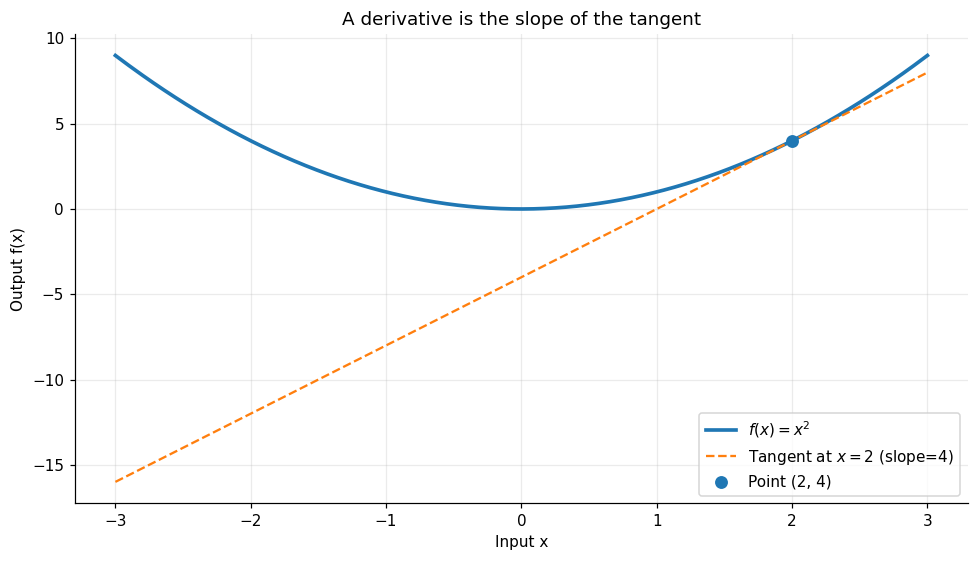

Saved figure: images/01_derivative_and_tangent.png


In [5]:
# Plot the function and its tangent line at x0 = 2.
x_plot = np.linspace(-3, 3, 300)
y_plot = x_plot ** 2
x0 = 2.0
y0 = x0 ** 2
gradient_at_x0 = 2 * x0
tangent = y0 + gradient_at_x0 * (x_plot - x0)

plt.figure()
plt.plot(x_plot, y_plot, label=r"$f(x)=x^2$", linewidth=2.4)
plt.plot(x_plot, tangent, label=fr"Tangent at $x={x0:g}$ (slope={gradient_at_x0:g})", linestyle="--")
plt.scatter([x0], [y0], s=55, zorder=3, label=fr"Point ({x0:g}, {y0:g})")
plt.xlabel("Input x")
plt.ylabel("Output f(x)")
plt.title("A derivative is the slope of the tangent")
plt.legend()
save_figure("01_derivative_and_tangent.png")

## 3. Your first Autograd derivative

Three ingredients matter:

- `requires_grad=True` asks PyTorch to track operations involving the tensor.
- The expression `y = x ** 2` creates a differentiable computation.
- `y.backward()` computes the derivative of the scalar output with respect to tracked leaf tensors. The result is stored in `x.grad`.

In [6]:
# Step 1 — create a scalar input that requires gradients.
x = torch.tensor(3.0, requires_grad=True)
x

tensor(3., requires_grad=True)

In [7]:
# Step 2 — perform an operation. PyTorch records the operation in the graph.
y = x ** 2
print("x:", x)
print("y:", y)
print("Does y require gradients?", y.requires_grad)
print("Grad function attached to y:", y.grad_fn)

x: tensor(3., requires_grad=True)
y: tensor(9., grad_fn=<PowBackward0>)
Does y require gradients? True
Grad function attached to y: <PowBackward0 object at 0x7ec25eb058a0>


In [8]:
# Step 3 — differentiate the scalar output with respect to x.
y.backward()
print("dy/dx at x=3:", x.grad)
print("Expected value 2x:", 2 * x.item())

dy/dx at x=3: tensor(6.)
Expected value 2x: 6.0


**Interpretation:** `x.grad` is `6`, because \(rac{d}{dx}x^2=2x\), and \(2\cdot3=6\).

A useful rule: `.backward()` normally expects a scalar output. Later, we will see what to do when the output is a vector.

In [9]:
# Compare several points: evaluate the function and its analytical derivative.
x_values = torch.tensor([-2.0, -1.0, 0.0, 1.0, 2.0, 3.0])
f_values = x_values ** 2
derivative_values = 2 * x_values

print(" x   | f(x)=x^2 | f'(x)=2x")
print("-----+---------+---------")
for xv, fv, dv in zip(x_values, f_values, derivative_values):
    print(f"{xv.item():>4.1f} | {fv.item():>7.2f} | {dv.item():>7.2f}")

 x   | f(x)=x^2 | f'(x)=2x
-----+---------+---------
-2.0 |    4.00 |   -4.00
-1.0 |    1.00 |   -2.00
 0.0 |    0.00 |    0.00
 1.0 |    1.00 |    2.00
 2.0 |    4.00 |    4.00
 3.0 |    9.00 |    6.00


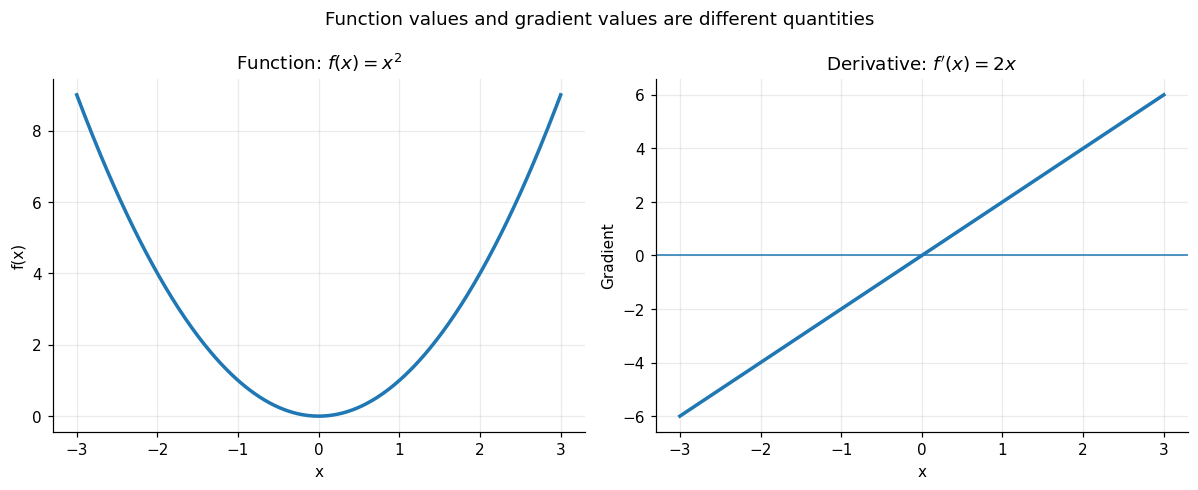

Saved figure: images/02_function_and_derivative.png


In [10]:
# Visualize both the function and its derivative.
xx = np.linspace(-3, 3, 300)
fig, ax = plt.subplots(1, 2, figsize=(11, 4.5))
ax[0].plot(xx, xx**2, linewidth=2.3)
ax[0].set_title(r"Function: $f(x)=x^2$")
ax[0].set_xlabel("x")
ax[0].set_ylabel("f(x)")
ax[1].plot(xx, 2*xx, linewidth=2.3)
ax[1].axhline(0, linewidth=1)
ax[1].set_title(r"Derivative: $f'(x)=2x$")
ax[1].set_xlabel("x")
ax[1].set_ylabel("Gradient")
plt.suptitle("Function values and gradient values are different quantities")
save_figure("02_function_and_derivative.png")

## 4. Computational graphs and the chain rule

Autograd handles nested expressions by applying the chain rule. Consider \(z=\sin(x^2)\). Define \(u=x^2\), then \(z=\sin(u)\). Therefore:

\[
rac{dz}{dx}=rac{dz}{du}rac{du}{dx}=\cos(x^2)\cdot2x.
\]

The next cells compare the manual derivative to PyTorch's result.

In [11]:
# One function, written as a sequence of intermediate steps.
x = torch.tensor(1.2, requires_grad=True)
u = x ** 2
z = torch.sin(u)

print("x =", x.item())
print("u = x^2 =", u.item())
print("z = sin(u) =", z.item())
print("z grad_fn:", z.grad_fn)

x = 1.2000000476837158
u = x^2 = 1.440000057220459
z = sin(u) = 0.9914583563804626
z grad_fn: <SinBackward0 object at 0x7ec26c0bb790>


In [12]:
# Differentiate the final scalar with respect to the original input.
z.backward()
autograd_derivative = x.grad.item()
manual_derivative = 2 * x.detach().item() * math.cos(x.detach().item() ** 2)

print(f"Autograd derivative : {autograd_derivative:.8f}")
print(f"Manual derivative   : {manual_derivative:.8f}")
print(f"Absolute difference : {abs(autograd_derivative - manual_derivative):.3e}")

Autograd derivative : 0.31301677
Manual derivative   : 0.31301664
Absolute difference : 1.312e-07


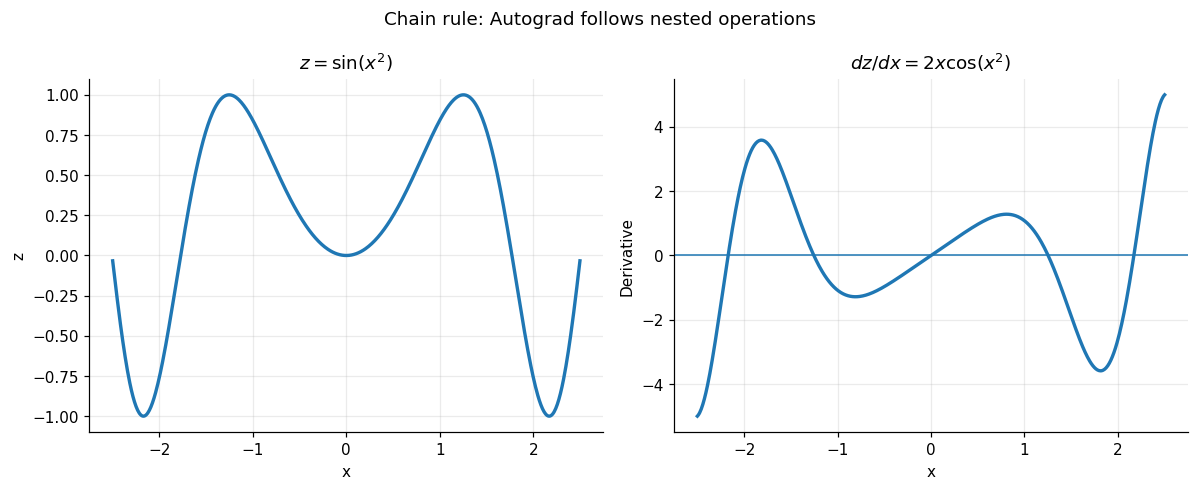

Saved figure: images/03_chain_rule_sin_x_squared.png


In [13]:
# Plot z = sin(x^2) and its derivative 2x cos(x^2).
xx = np.linspace(-2.5, 2.5, 600)
zz = np.sin(xx**2)
dzz = 2 * xx * np.cos(xx**2)
fig, ax = plt.subplots(1, 2, figsize=(11, 4.5))
ax[0].plot(xx, zz, linewidth=2.2)
ax[0].set_title(r"$z=\sin(x^2)$")
ax[0].set_xlabel("x")
ax[0].set_ylabel("z")
ax[1].plot(xx, dzz, linewidth=2.2)
ax[1].axhline(0, linewidth=1)
ax[1].set_title(r"$dz/dx=2x\cos(x^2)$")
ax[1].set_xlabel("x")
ax[1].set_ylabel("Derivative")
plt.suptitle("Chain rule: Autograd follows nested operations")
save_figure("03_chain_rule_sin_x_squared.png")

In [14]:
# A simple manual-versus-Autograd check over several x values.
def compare_chain_rule(x_value: float):
    x = torch.tensor(float(x_value), requires_grad=True)
    torch.sin(x ** 2).backward()
    auto = x.grad.item()
    manual = 2 * x_value * math.cos(x_value ** 2)
    return auto, manual

for point in [0.2, 0.7, 1.2, 2.0]:
    auto, manual = compare_chain_rule(point)
    print(f"x={point:>3.1f} | Autograd={auto: .7f} | manual={manual: .7f}")

x=0.2 | Autograd= 0.3996800 | manual= 0.3996800
x=0.7 | Autograd= 1.2352660 | manual= 1.2352660
x=1.2 | Autograd= 0.3130168 | manual= 0.3130169
x=2.0 | Autograd=-2.6145744 | manual=-2.6145745


## 5. Multiple inputs and vector computations

Autograd can differentiate a scalar loss with respect to several inputs. For a simple example, \(L=a^2+3b\), the derivatives are \(\partial L/\partial a=2a\) and \(\partial L/\partial b=3\).

In [15]:
a = torch.tensor(2.0, requires_grad=True)
b = torch.tensor(4.0, requires_grad=True)
loss = a**2 + 3*b

print("loss =", loss.item())
loss.backward()
print("dL/da =", a.grad.item(), "(expected", 2*a.item(), ")")
print("dL/db =", b.grad.item(), "(expected 3)")

loss = 16.0
dL/da = 4.0 (expected 4.0 )
dL/db = 3.0 (expected 3)


In [16]:
# A vector tensor can participate in a scalar loss.
values = torch.tensor([1.0, 2.0, 3.0], requires_grad=True)
mean_square = (values ** 2).mean()
mean_square.backward()

print("Values:", values.detach().tolist())
print("Mean of squares:", mean_square.item())
print("Gradient:", values.grad.tolist())
print("Expected gradient 2*x/n:", (2 * values.detach() / values.numel()).tolist())

Values: [1.0, 2.0, 3.0]
Mean of squares: 4.666666507720947
Gradient: [0.6666666865348816, 1.3333333730697632, 2.0]
Expected gradient 2*x/n: [0.6666666865348816, 1.3333333730697632, 2.0]


For a mean-squared expression \(L=rac{1}{n}\sum_i x_i^2\), each input gradient is \(2x_i/n\). Reduction operations such as `.mean()` and `.sum()` turn vector values into a scalar loss, which is why they are common before `.backward()` in training loops.

In [17]:
# Compare sum and mean reductions; the gradient scale changes with the reduction.
x_sum = torch.tensor([1.0, 2.0, 3.0], requires_grad=True)
x_mean = torch.tensor([1.0, 2.0, 3.0], requires_grad=True)

x_sum.square().sum().backward()
x_mean.square().mean().backward()

print("Gradient after sum :", x_sum.grad.tolist())
print("Gradient after mean:", x_mean.grad.tolist())

Gradient after sum : [2.0, 4.0, 6.0]
Gradient after mean: [0.6666666865348816, 1.3333333730697632, 2.0]


### 5.1 What if the output is not a scalar?

For a vector output, PyTorch needs an upstream gradient that describes how to combine the output elements. Calling `y.backward(torch.ones_like(y))` computes the vector-Jacobian product corresponding to summing the output components. That is also the result of calling `.sum().backward()`.

In [18]:
x = torch.tensor([1.0, 2.0, 3.0], requires_grad=True)
y = x ** 2
print("Vector output y:", y)
print("Output shape:", tuple(y.shape))

# Supply the upstream gradient explicitly: one for every output entry.
y.backward(torch.ones_like(y))
print("Vector-Jacobian product / gradient:", x.grad)

Vector output y: tensor([1., 4., 9.], grad_fn=<PowBackward0>)
Output shape: (3,)
Vector-Jacobian product / gradient: tensor([2., 4., 6.])


In [19]:
# Equivalent expression: differentiate the sum of the vector outputs.
x = torch.tensor([1.0, 2.0, 3.0], requires_grad=True)
(x ** 2).sum().backward()
print("Gradient from sum().backward():", x.grad)

Gradient from sum().backward(): tensor([2., 4., 6.])


### 5.2 Jacobian matrix (optional intermediate topic)

A Jacobian records how every output component changes with every input component. It is useful for understanding multi-output functions, though large neural networks usually avoid constructing the full Jacobian because it can be expensive.

In [20]:
def two_output_function(inputs):
    # inputs = [u, v]
    u, v = inputs[0], inputs[1]
    return torch.stack([u**2 + v, u*v])

point = torch.tensor([2.0, 3.0], requires_grad=True)
jacobian = torch.autograd.functional.jacobian(two_output_function, point)
print("Input point:", point)
print("Jacobian shape:", tuple(jacobian.shape))
print(jacobian)
print("Rows correspond to outputs; columns correspond to inputs.")

Input point: tensor([2., 3.], requires_grad=True)
Jacobian shape: (2, 2)
tensor([[4., 1.],
        [3., 2.]])
Rows correspond to outputs; columns correspond to inputs.


## 6. Gradient accumulation and graph lifetime

One of the most important Autograd details: **`.backward()` adds to an existing `.grad` value; it does not automatically reset the gradient.** Training loops should normally clear gradients before each new backward pass.

Also, PyTorch frees much of a computation graph after `.backward()` by default. To differentiate a new expression, recompute it rather than trying to reuse a graph that has already been consumed.

In [21]:
# First backward pass.
x = torch.tensor(2.0, requires_grad=True)
(x ** 2).backward()
print("After d(x^2)/dx:", x.grad.item())  # 2x = 4

After d(x^2)/dx: 4.0


In [22]:
# Second backward pass from a new expression adds to the existing gradient.
(x ** 3).backward()
print("After also differentiating x^3:", x.grad.item())
print("Expected accumulated result: 2x + 3x^2 =", 2*2 + 3*(2**2))

After also differentiating x^3: 16.0
Expected accumulated result: 2x + 3x^2 = 16


In [23]:
# Clear the old gradient, then compute only the derivative of x^3.
x.grad.zero_()
(x ** 3).backward()
print("After zeroing and differentiating x^3:", x.grad.item())

After zeroing and differentiating x^3: 12.0


In [24]:
# Recommended training-loop pattern: clear -> forward -> loss -> backward -> update.
parameter = torch.tensor(1.5, requires_grad=True)
learning_rate = 0.1

parameter.grad = None  # also a valid way to clear gradients
loss = (parameter - 5) ** 2
loss.backward()
print("Parameter before update:", parameter.item())
print("Gradient:", parameter.grad.item())
with torch.no_grad():
    parameter -= learning_rate * parameter.grad
print("Parameter after one SGD-style update:", parameter.item())

Parameter before update: 1.5
Gradient: -7.0
Parameter after one SGD-style update: 2.200000047683716


## 7. Controlling gradient tracking

Three related tools serve different purposes:

- `tensor.requires_grad_(False)`: stop tracking operations on that tensor going forward.
- `tensor.detach()`: create a tensor sharing the same underlying data but disconnected from the current autograd graph.
- `with torch.no_grad():`: temporarily disable gradient tracking inside a block, commonly used for parameter updates and inference-style calculations.

These tools do not mean the same thing. The examples below show the resulting `requires_grad` flags.

In [25]:
# requires_grad_ changes tracking behavior on the tensor.
x = torch.tensor(2.0, requires_grad=True)
print("Initially:", x.requires_grad)
x.requires_grad_(False)
print("After requires_grad_(False):", x.requires_grad)
y = x ** 2
print("y.requires_grad:", y.requires_grad)
print("y.grad_fn:", y.grad_fn)

Initially: True
After requires_grad_(False): False
y.requires_grad: False
y.grad_fn: None


In [26]:
# detach() produces a graph-disconnected view of the tensor data.
x = torch.tensor(2.0, requires_grad=True)
y = x ** 2
x_detached = x.detach()
y_from_detached = x_detached ** 2

print("x requires grad:", x.requires_grad)
print("x_detached requires grad:", x_detached.requires_grad)
print("y requires grad:", y.requires_grad)
print("y_from_detached requires grad:", y_from_detached.requires_grad)

x requires grad: True
x_detached requires grad: False
y requires grad: True
y_from_detached requires grad: False


In [27]:
# no_grad() temporarily disables graph recording in its context.
x = torch.tensor(2.0, requires_grad=True)
y_tracked = x ** 2
with torch.no_grad():
    y_untracked = x ** 2

print("Tracked expression requires grad:", y_tracked.requires_grad)
print("Expression inside no_grad requires grad:", y_untracked.requires_grad)

Tracked expression requires grad: True
Expression inside no_grad requires grad: False


In [28]:
# detach is commonly useful when converting a result to NumPy for plotting.
x = torch.linspace(-2, 2, 5, requires_grad=True)
y = x ** 2
x_np = x.detach().cpu().numpy()
y_np = y.detach().cpu().numpy()
print("Converted arrays:", x_np, y_np)

Converted arrays: [-2. -1.  0.  1.  2.] [4. 1. 0. 1. 4.]


### 7.1 Leaf tensors and intermediate tensors

A leaf tensor is typically a tensor created directly by the user with `requires_grad=True`. Its `.grad` is populated automatically after backpropagation. Intermediate, non-leaf tensors participate in the graph, but their `.grad` is not retained by default unless `.retain_grad()` is called.

In [29]:
x = torch.tensor(3.0, requires_grad=True)  # leaf tensor
y = x * 2                                   # intermediate tensor
z = y ** 2

y.retain_grad()  # ask PyTorch to store y's gradient too
z.backward()

print("x is leaf:", x.is_leaf, "| x.grad:", x.grad.item())
print("y is leaf:", y.is_leaf, "| y.grad:", y.grad.item())
print("z is leaf:", z.is_leaf)

x is leaf: True | x.grad: 24.0
y is leaf: False | y.grad: 12.0
z is leaf: False


## 8. Verify Autograd with finite differences

A central finite-difference approximation for a scalar function is:

\[
f'(x)pprox rac{f(x+h)-f(x-h)}{2h}.
\]

This is not as accurate or efficient as symbolic/automatic differentiation for model training, but it is an excellent debugging tool for small examples. Very large or very small values of \(h\) can increase numerical error.

In [30]:
def function_for_check(x):
    return torch.sin(x ** 2)

x0 = 1.1
x_autograd = torch.tensor(x0, requires_grad=True)
function_for_check(x_autograd).backward()
auto_gradient = x_autograd.grad.item()

h = 1e-4
with torch.no_grad():
    x_tensor = torch.tensor(x0)
    plus = function_for_check(x_tensor + h).item()
    minus = function_for_check(x_tensor - h).item()
finite_difference = (plus - minus) / (2 * h)

print(f"Autograd gradient       : {auto_gradient:.10f}")
print(f"Central difference      : {finite_difference:.10f}")
print(f"Absolute error           : {abs(auto_gradient - finite_difference):.3e}")

Autograd gradient       : 0.7766426206
Central difference      : 0.7769465446
Absolute error           : 3.039e-04


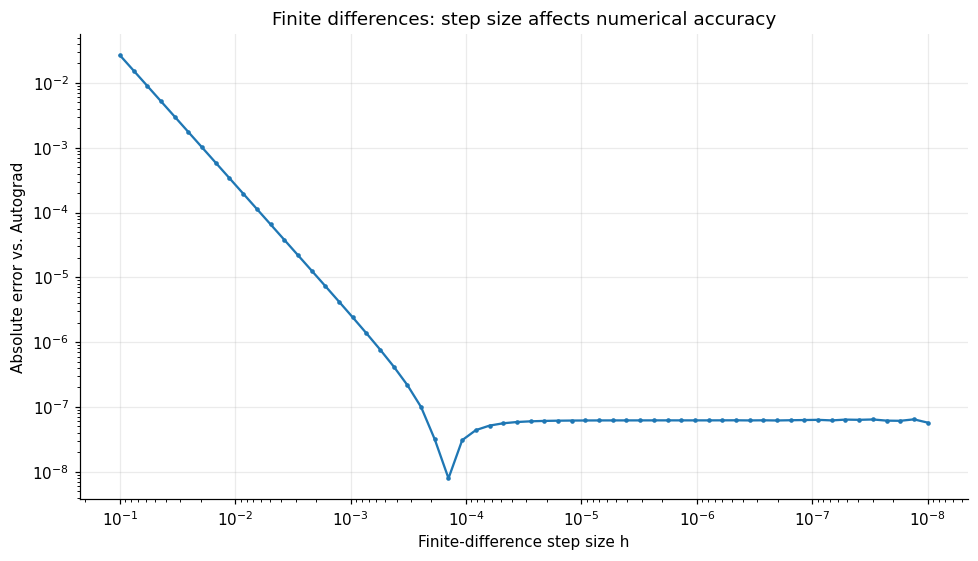

Saved figure: images/04_finite_difference_error.png


In [31]:
# Investigate how the approximation changes as h changes.
x0 = 1.1
x_ref = torch.tensor(x0, requires_grad=True)
function_for_check(x_ref).backward()
reference = x_ref.grad.item()
h_values = np.logspace(-1, -8, 60)
errors = []
with torch.no_grad():
    for h in h_values:
        plus = function_for_check(torch.tensor(x0 + h)).item()
        minus = function_for_check(torch.tensor(x0 - h)).item()
        estimate = (plus - minus) / (2 * h)
        errors.append(abs(estimate - reference))

plt.figure()
plt.loglog(h_values, errors, marker=".", markersize=4, linewidth=1.5)
plt.xlabel("Finite-difference step size h")
plt.ylabel("Absolute error vs. Autograd")
plt.title("Finite differences: step size affects numerical accuracy")
plt.gca().invert_xaxis()
save_figure("04_finite_difference_error.png")

**Takeaway:** a gradient check is most useful on a small, deterministic example. For neural networks, compare manual/numerical gradients only on a tiny model and a tiny batch; full gradient checking can be expensive.

## 9. Binary cross-entropy: from formulas to Autograd

Binary cross-entropy (BCE) compares a predicted probability \(p\) with a target \(y\in\{0,1\}\):

\[
L(p,y)=-\left[y\log(p)+(1-y)\log(1-p)
ight].
\]

In practice, prefer `torch.nn.BCEWithLogitsLoss` when you have raw logits. It combines sigmoid and BCE in a numerically stable operation. We will first examine the probability-space formula, then use logits for model training.

In [32]:
# A transparent scalar BCE implementation for teaching purposes.
def binary_cross_entropy_probability(probability, target, eps=1e-7):
    probability = torch.clamp(probability, eps, 1 - eps)
    return -(target * torch.log(probability) + (1 - target) * torch.log(1 - probability))

for target_value in [0.0, 1.0]:
    p = torch.tensor(0.8)
    target = torch.tensor(target_value)
    print(f"p={p.item():.1f}, target={target_value:.0f}, BCE={binary_cross_entropy_probability(p, target).item():.4f}")

p=0.8, target=0, BCE=1.6094
p=0.8, target=1, BCE=0.2231


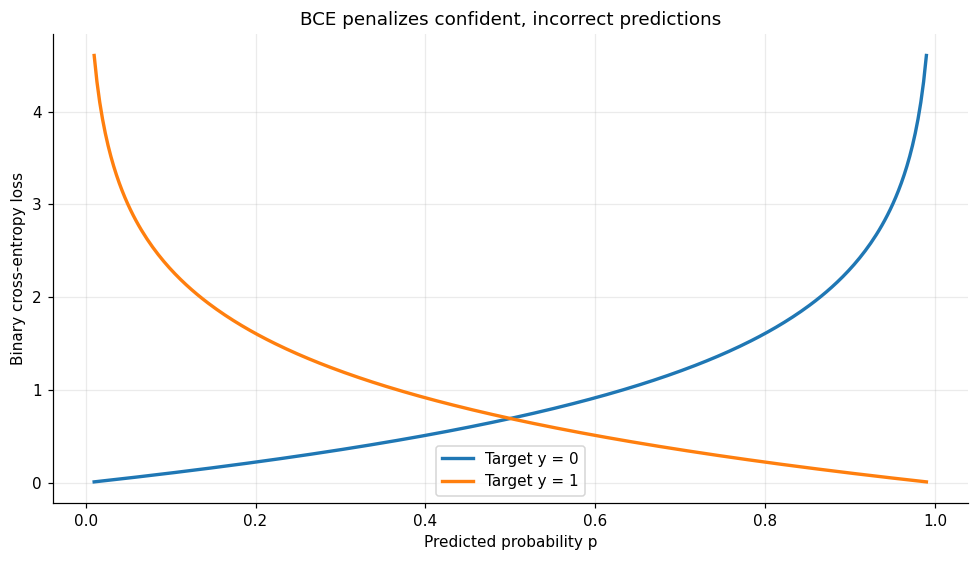

Saved figure: images/05_binary_cross_entropy.png


In [33]:
# Plot BCE as a function of predicted probability for each target class.
probabilities = np.linspace(0.01, 0.99, 300)
loss_target_zero = -np.log(1 - probabilities)
loss_target_one = -np.log(probabilities)

plt.figure()
plt.plot(probabilities, loss_target_zero, label="Target y = 0", linewidth=2.2)
plt.plot(probabilities, loss_target_one, label="Target y = 1", linewidth=2.2)
plt.xlabel("Predicted probability p")
plt.ylabel("Binary cross-entropy loss")
plt.title("BCE penalizes confident, incorrect predictions")
plt.legend()
save_figure("05_binary_cross_entropy.png")

In [34]:
# A single sigmoid neuron: z = w*x + b, p = sigmoid(z), then BCE loss.
feature = torch.tensor(6.7)
target = torch.tensor(0.0)
weight = torch.tensor(1.0, requires_grad=True)
bias = torch.tensor(0.0, requires_grad=True)

logit = weight * feature + bias
probability = torch.sigmoid(logit)
loss = binary_cross_entropy_probability(probability, target)

print(f"Logit              : {logit.item():.6f}")
print(f"Predicted probability: {probability.item():.6f}")
print(f"BCE loss            : {loss.item():.6f}")

Logit              : 6.700000
Predicted probability: 0.998771
BCE loss            : 6.701176


In [35]:
# Backpropagate the loss into the weight and bias.
loss.backward()
print("Autograd dL/dw:", weight.grad.item())
print("Autograd dL/db:", bias.grad.item())

# For sigmoid + BCE, dL/dz = p - y.
manual_dz = probability.detach() - target
manual_dw = manual_dz * feature
manual_db = manual_dz
print("Manual dL/dw  :", manual_dw.item())
print("Manual dL/db  :", manual_db.item())

Autograd dL/dw: 6.6917619705200195
Autograd dL/db: 0.9987704753875732
Manual dL/dw  : 6.691762447357178
Manual dL/db  : 0.998770534992218


The hand-derived gradients and Autograd gradients should agree up to floating-point rounding. This is a useful pattern for debugging: write down the small formula, derive the gradient, and compare against Autograd before scaling up to a full model.

In [36]:
# Preferred API for training: BCEWithLogitsLoss receives logits (not sigmoid probabilities).
logits_demo = torch.tensor([0.0, 2.0, -2.0])
targets_demo = torch.tensor([0.0, 1.0, 0.0])
loss_fn = nn.BCEWithLogitsLoss()
stable_loss = loss_fn(logits_demo, targets_demo)
print("Logits:", logits_demo)
print("Targets:", targets_demo)
print("Mean BCEWithLogitsLoss:", stable_loss.item())

Logits: tensor([ 0.,  2., -2.])
Targets: tensor([0., 1., 0.])
Mean BCEWithLogitsLoss: 0.3156677782535553


## 10. Train logistic regression with Autograd

We will generate a tiny, synthetic two-class dataset. The model computes \(z=Xw+b\); `BCEWithLogitsLoss` computes the loss; `.backward()` computes gradients; SGD updates the parameters. No external dataset is needed.

In [37]:
# Generate two slightly overlapping clusters with two features.
torch.manual_seed(SEED)
n_per_class = 120
class_zero = torch.randn(n_per_class, 2) * 0.85 + torch.tensor([-1.0, -0.8])
class_one = torch.randn(n_per_class, 2) * 0.85 + torch.tensor([1.0, 0.9])
X_cls = torch.cat([class_zero, class_one], dim=0)
y_cls = torch.cat([torch.zeros(n_per_class), torch.ones(n_per_class)]).unsqueeze(1)

permutation = torch.randperm(X_cls.shape[0])
X_cls, y_cls = X_cls[permutation], y_cls[permutation]
print("Feature matrix shape:", tuple(X_cls.shape))
print("Target shape        :", tuple(y_cls.shape))
print("Class-1 proportion  :", y_cls.mean().item())

Feature matrix shape: (240, 2)
Target shape        : (240, 1)
Class-1 proportion  : 0.5


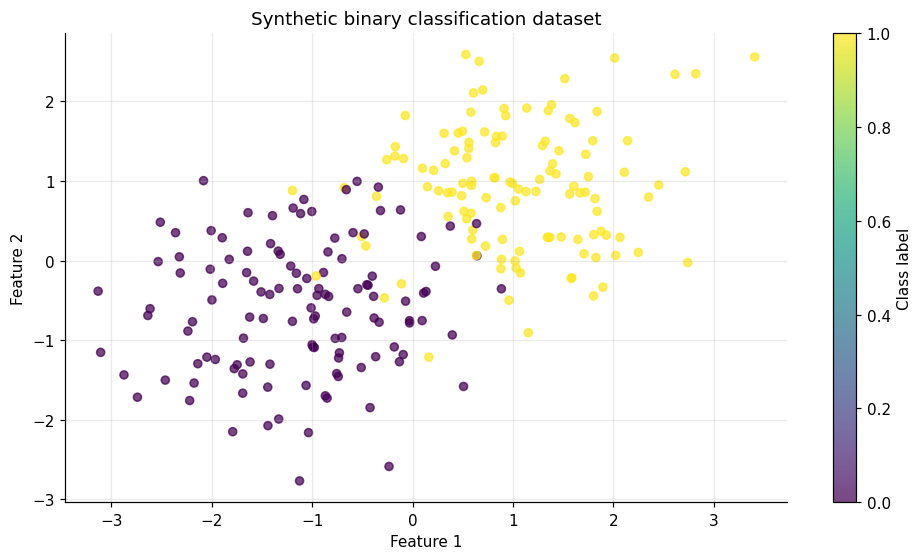

Saved figure: images/06_logistic_dataset.png


In [38]:
# Plot the dataset before training.
labels_np = y_cls.squeeze(1).numpy()
plt.figure()
plt.scatter(X_cls[:, 0].numpy(), X_cls[:, 1].numpy(), c=labels_np, alpha=0.72, s=28)
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.title("Synthetic binary classification dataset")
plt.colorbar(label="Class label")
save_figure("06_logistic_dataset.png")

In [39]:
# Model parameters are leaf tensors with gradients enabled.
weights = nn.Parameter(torch.zeros(2, 1))
bias = nn.Parameter(torch.zeros(1))
optimizer = torch.optim.SGD([weights, bias], lr=0.1)
criterion = nn.BCEWithLogitsLoss()

print("Initial weights:", weights.detach().flatten().tolist())
print("Initial bias   :", bias.item())

Initial weights: [0.0, 0.0]
Initial bias   : 0.0


In [40]:
# Full-batch training loop. Include the untrained model at epoch 0 for an honest baseline.
num_epochs = 250
with torch.no_grad():
    initial_logits = X_cls @ weights + bias
    classification_losses = [criterion(initial_logits, y_cls).item()]
    initial_predictions = (torch.sigmoid(initial_logits) >= 0.5).float()
    classification_accuracies = [(initial_predictions == y_cls).float().mean().item()]

for epoch in range(num_epochs):
    optimizer.zero_grad(set_to_none=True)       # 1) clear old gradients
    logits = X_cls @ weights + bias             # 2) forward pass
    loss = criterion(logits, y_cls)             # 3) calculate scalar loss
    loss.backward()                             # 4) automatic differentiation
    optimizer.step()                            # 5) update parameters

    # Measure the updated model so loss and accuracy refer to the same parameters.
    with torch.no_grad():
        updated_logits = X_cls @ weights + bias
        updated_loss = criterion(updated_logits, y_cls)
        probabilities = torch.sigmoid(updated_logits)
        predictions = (probabilities >= 0.5).float()
        accuracy = (predictions == y_cls).float().mean()
        classification_losses.append(updated_loss.item())
        classification_accuracies.append(accuracy.item())

print(f"Final loss    : {classification_losses[-1]:.4f}")
print(f"Final accuracy: {classification_accuracies[-1]:.1%}")
print("Learned weights:", weights.detach().flatten().tolist())
print("Learned bias   :", bias.item())

Final loss    : 0.1702
Final accuracy: 92.5%
Learned weights: [1.9791699647903442, 1.432928442955017]
Learned bias   : -0.17475932836532593


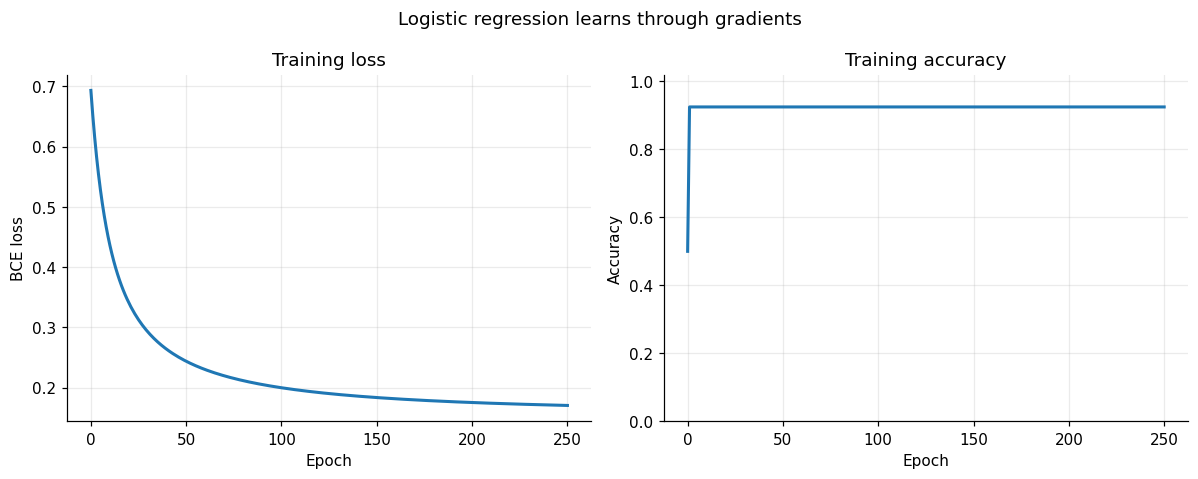

Saved figure: images/07_logistic_training_curves.png


In [41]:
# Visualize the learning curves.
fig, ax = plt.subplots(1, 2, figsize=(11, 4.4))
ax[0].plot(classification_losses, linewidth=2)
ax[0].set_title("Training loss")
ax[0].set_xlabel("Epoch")
ax[0].set_ylabel("BCE loss")
ax[1].plot(classification_accuracies, linewidth=2)
ax[1].set_title("Training accuracy")
ax[1].set_xlabel("Epoch")
ax[1].set_ylabel("Accuracy")
ax[1].set_ylim(0, 1.02)
plt.suptitle("Logistic regression learns through gradients")
save_figure("07_logistic_training_curves.png")

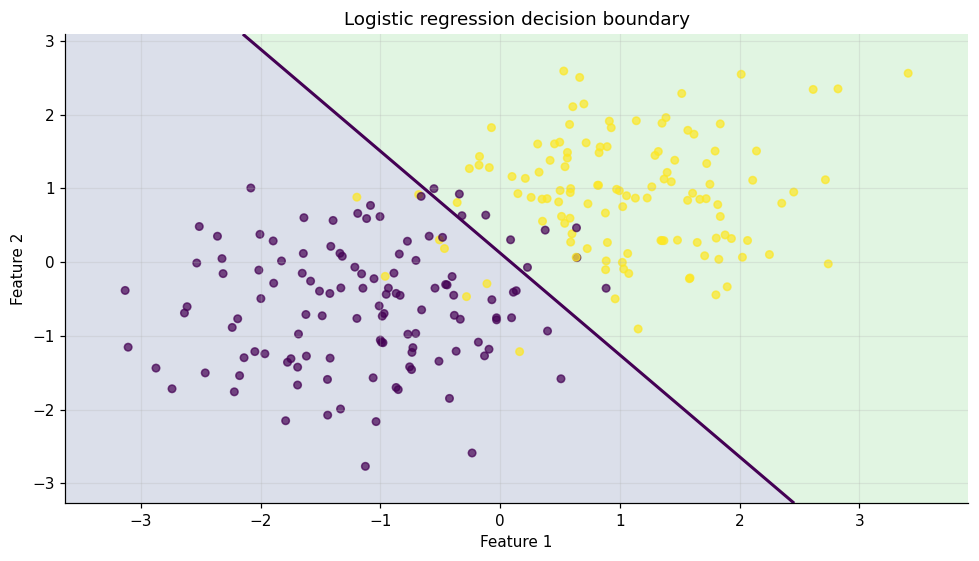

Saved figure: images/08_logistic_decision_boundary.png


In [42]:
# Plot the learned decision boundary over the same dataset.
with torch.no_grad():
    w_np = weights.detach().flatten().numpy()
    b_np = bias.item()
    x_min, x_max = X_cls[:, 0].min().item() - 0.5, X_cls[:, 0].max().item() + 0.5
    y_min, y_max = X_cls[:, 1].min().item() - 0.5, X_cls[:, 1].max().item() + 0.5
    gx, gy = np.meshgrid(np.linspace(x_min, x_max, 250), np.linspace(y_min, y_max, 250))
    score = w_np[0] * gx + w_np[1] * gy + b_np

plt.figure()
plt.contourf(gx, gy, score, levels=[-100, 0, 100], alpha=0.18)
plt.contour(gx, gy, score, levels=[0], linewidths=2)
plt.scatter(X_cls[:, 0].numpy(), X_cls[:, 1].numpy(), c=labels_np, alpha=0.7, s=24)
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.title("Logistic regression decision boundary")
save_figure("08_logistic_decision_boundary.png")

## 11. Linear regression: watch Autograd train a model

Now use a continuous target. We create synthetic data from approximately \(y=1.8x-0.7\), add noise, then train a linear model \(\hat y=wx+b\) using mean squared error.

The training loop follows a standard pattern: **zero gradients → forward pass → loss → backward pass → optimizer step**.

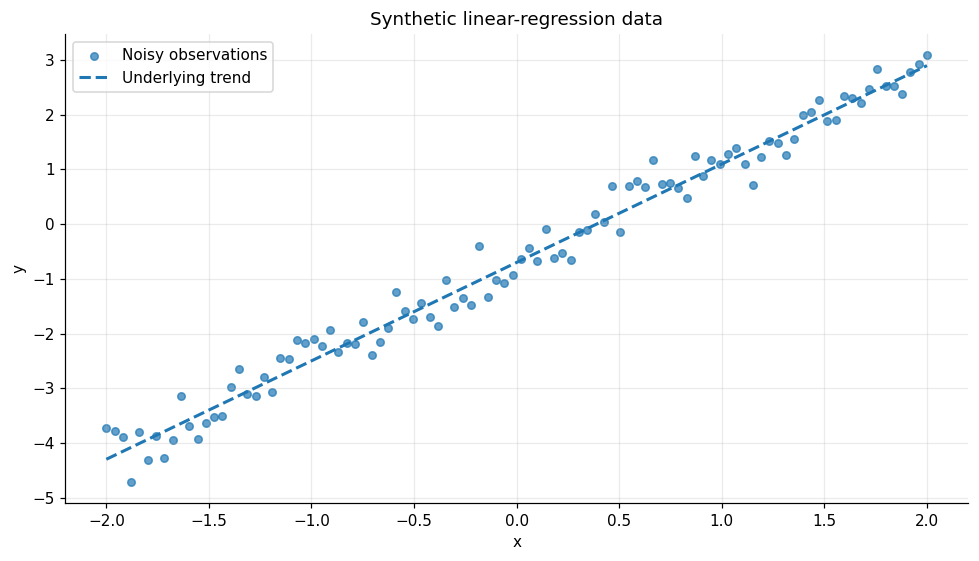

Saved figure: images/09_linear_regression_dataset.png


In [43]:
# Create a reproducible toy regression dataset.
torch.manual_seed(SEED)
X_reg = torch.linspace(-2, 2, 100).unsqueeze(1)
y_reg = 1.8 * X_reg - 0.7 + 0.3 * torch.randn_like(X_reg)

plt.figure()
plt.scatter(X_reg.numpy(), y_reg.numpy(), alpha=0.7, s=24, label="Noisy observations")
plt.plot(X_reg.numpy(), (1.8 * X_reg - 0.7).numpy(), linestyle="--", linewidth=2, label="Underlying trend")
plt.xlabel("x")
plt.ylabel("y")
plt.title("Synthetic linear-regression data")
plt.legend()
save_figure("09_linear_regression_dataset.png")

In [44]:
# Define trainable scalar weight and bias.
weight_reg = nn.Parameter(torch.randn(1))
bias_reg = nn.Parameter(torch.zeros(1))
optimizer_reg = torch.optim.SGD([weight_reg, bias_reg], lr=0.05)
loss_fn_reg = nn.MSELoss()

print("Initial weight:", weight_reg.item())
print("Initial bias  :", bias_reg.item())

Initial weight: -0.5671805739402771
Initial bias  : 0.0


In [45]:
# Train by repeatedly differentiating the MSE loss.
reg_epochs = 250
reg_loss_history = []

for epoch in range(reg_epochs):
    optimizer_reg.zero_grad(set_to_none=True)
    predictions_reg = X_reg * weight_reg + bias_reg
    loss_reg = loss_fn_reg(predictions_reg, y_reg)
    loss_reg.backward()
    optimizer_reg.step()
    reg_loss_history.append(loss_reg.item())

print(f"Final MSE: {reg_loss_history[-1]:.6f}")
print(f"Learned weight: {weight_reg.item():.4f} (target trend ≈ 1.8)")
print(f"Learned bias  : {bias_reg.item():.4f} (target trend ≈ -0.7)")

Final MSE: 0.086661
Learned weight: 1.7956 (target trend ≈ 1.8)
Learned bias  : -0.6821 (target trend ≈ -0.7)


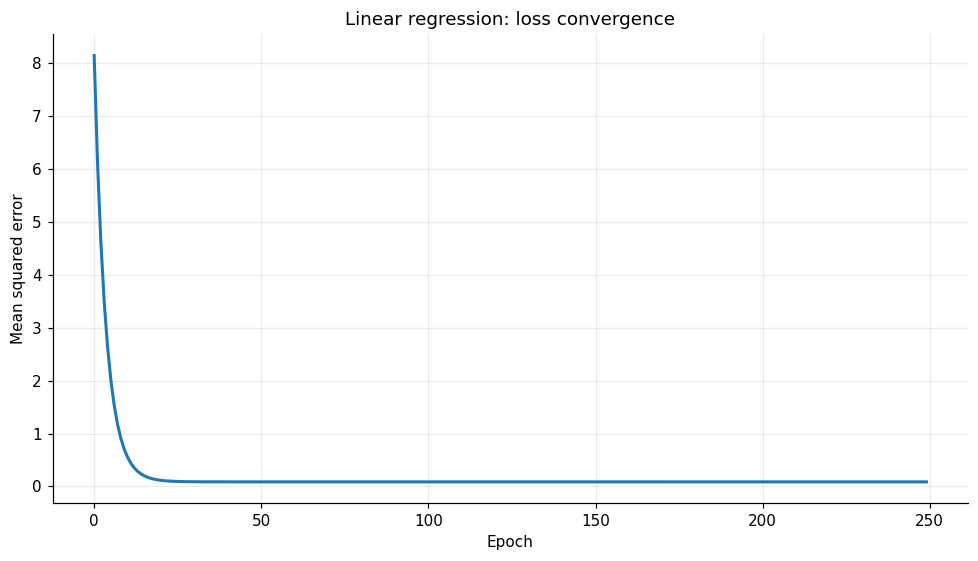

Saved figure: images/10_linear_regression_loss.png


In [46]:
# Plot loss over training epochs.
plt.figure()
plt.plot(reg_loss_history, linewidth=2)
plt.xlabel("Epoch")
plt.ylabel("Mean squared error")
plt.title("Linear regression: loss convergence")
save_figure("10_linear_regression_loss.png")

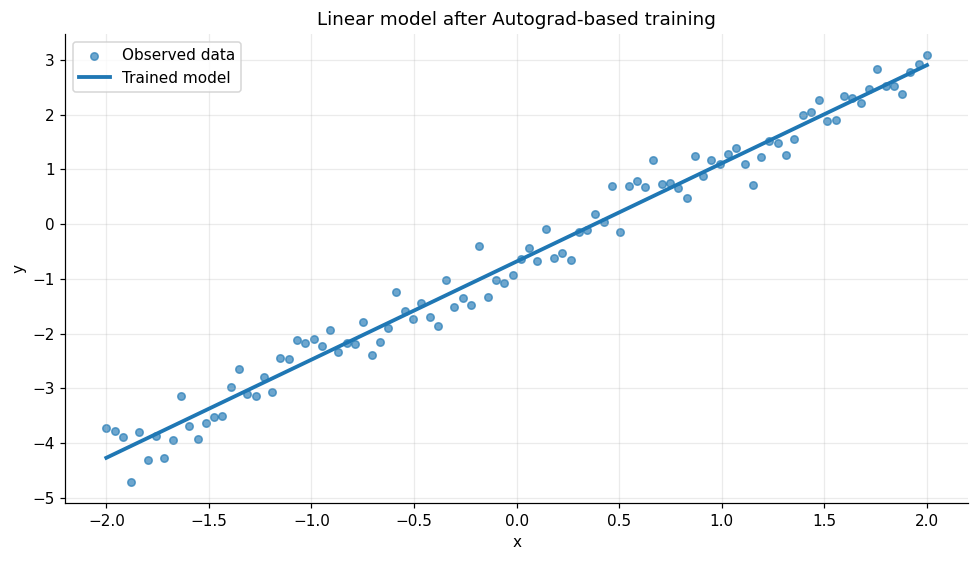

Saved figure: images/11_linear_regression_fit.png


In [47]:
# Compare model predictions with observed data.
with torch.no_grad():
    fitted_reg = X_reg * weight_reg + bias_reg

plt.figure()
plt.scatter(X_reg.numpy(), y_reg.numpy(), alpha=0.65, s=24, label="Observed data")
plt.plot(X_reg.numpy(), fitted_reg.numpy(), linewidth=2.5, label="Trained model")
plt.xlabel("x")
plt.ylabel("y")
plt.title("Linear model after Autograd-based training")
plt.legend()
save_figure("11_linear_regression_fit.png")

## 12. A small neural network: gradients reach multiple layers

A neural network is a composition of differentiable operations. Autograd applies the chain rule through all tracked layers. This small multilayer perceptron uses two linear layers and a `Tanh` activation to learn the same synthetic two-class task.

This section is deliberately small enough to run quickly on a CPU.

In [48]:
# Reset the seed so this experiment is repeatable.
torch.manual_seed(SEED)
mlp = nn.Sequential(
    nn.Linear(2, 16),
    nn.Tanh(),
    nn.Linear(16, 1),
)
mlp_loss_fn = nn.BCEWithLogitsLoss()
mlp_optimizer = torch.optim.Adam(mlp.parameters(), lr=0.03)

print(mlp)
print("Trainable parameters:", sum(p.numel() for p in mlp.parameters() if p.requires_grad))

Sequential(
  (0): Linear(in_features=2, out_features=16, bias=True)
  (1): Tanh()
  (2): Linear(in_features=16, out_features=1, bias=True)
)
Trainable parameters: 65


In [49]:
# Train the MLP and record a baseline plus each post-update metric.
mlp_epochs = 180
with torch.no_grad():
    initial_mlp_logits = mlp(X_cls)
    mlp_losses = [mlp_loss_fn(initial_mlp_logits, y_cls).item()]
    initial_mlp_predictions = (torch.sigmoid(initial_mlp_logits) >= 0.5).float()
    mlp_accuracies = [(initial_mlp_predictions == y_cls).float().mean().item()]

for epoch in range(mlp_epochs):
    mlp_optimizer.zero_grad(set_to_none=True)
    logits_mlp = mlp(X_cls)
    loss_mlp = mlp_loss_fn(logits_mlp, y_cls)
    loss_mlp.backward()
    mlp_optimizer.step()

    with torch.no_grad():
        updated_logits_mlp = mlp(X_cls)
        updated_loss_mlp = mlp_loss_fn(updated_logits_mlp, y_cls)
        predicted_classes = (torch.sigmoid(updated_logits_mlp) >= 0.5).float()
        accuracy_mlp = (predicted_classes == y_cls).float().mean()
        mlp_losses.append(updated_loss_mlp.item())
        mlp_accuracies.append(accuracy_mlp.item())

print(f"Final MLP loss    : {mlp_losses[-1]:.4f}")
print(f"Final MLP accuracy: {mlp_accuracies[-1]:.1%}")

Final MLP loss    : 0.1453
Final MLP accuracy: 93.8%


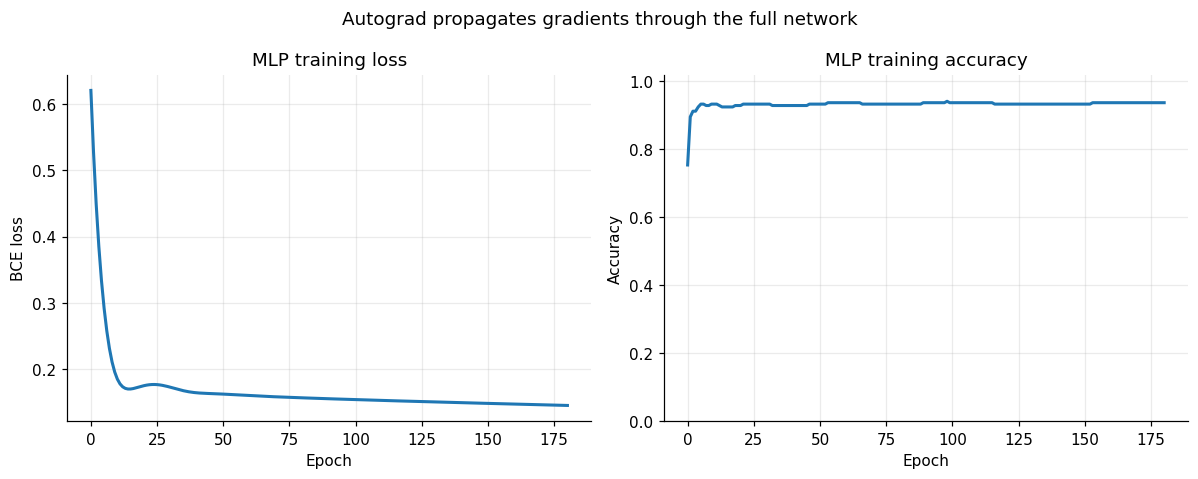

Saved figure: images/12_mlp_training_curves.png


In [50]:
# Show learning curves side by side.
fig, ax = plt.subplots(1, 2, figsize=(11, 4.4))
ax[0].plot(mlp_losses, linewidth=2)
ax[0].set_title("MLP training loss")
ax[0].set_xlabel("Epoch")
ax[0].set_ylabel("BCE loss")
ax[1].plot(mlp_accuracies, linewidth=2)
ax[1].set_title("MLP training accuracy")
ax[1].set_xlabel("Epoch")
ax[1].set_ylabel("Accuracy")
ax[1].set_ylim(0, 1.02)
plt.suptitle("Autograd propagates gradients through the full network")
save_figure("12_mlp_training_curves.png")

0.weight                 | shape=(16, 2)      | grad norm=0.002934
0.bias                   | shape=(16,)        | grad norm=0.001014
2.weight                 | shape=(1, 16)      | grad norm=0.003365
2.bias                   | shape=(1,)         | grad norm=0.000414


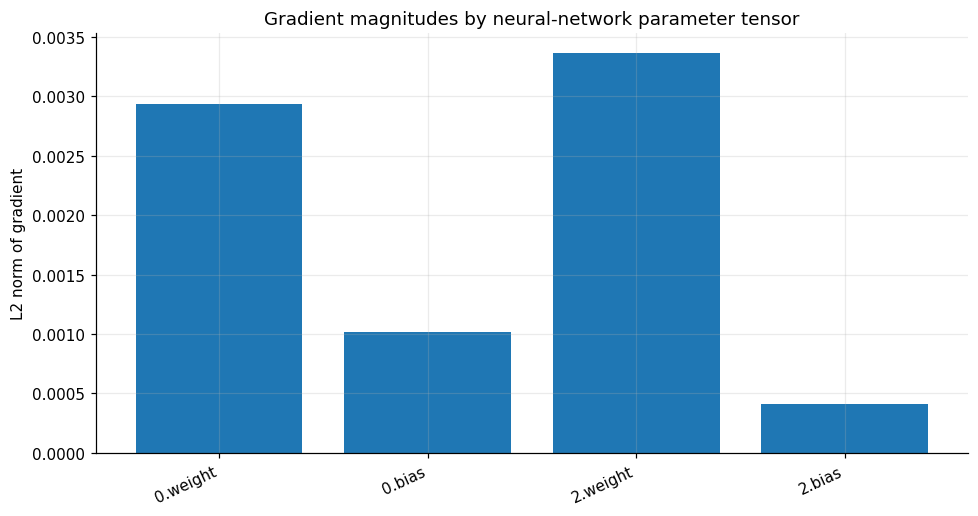

Saved figure: images/13_mlp_gradient_norms.png


In [51]:
# Inspect gradient magnitudes after a fresh backward pass.
mlp_optimizer.zero_grad(set_to_none=True)
mlp_loss_fn(mlp(X_cls), y_cls).backward()

parameter_names = []
gradient_norms = []
for name, parameter in mlp.named_parameters():
    parameter_names.append(name)
    gradient_norms.append(parameter.grad.detach().norm().item())
    print(f"{name:24s} | shape={tuple(parameter.shape)!s:12s} | grad norm={gradient_norms[-1]:.6f}")

plt.figure(figsize=(9, 4.8))
plt.bar(parameter_names, gradient_norms)
plt.xticks(rotation=25, ha="right")
plt.ylabel("L2 norm of gradient")
plt.title("Gradient magnitudes by neural-network parameter tensor")
save_figure("13_mlp_gradient_norms.png")

**How to read the gradient-norm plot:** a nonzero gradient indicates that the current loss has a path to that parameter. A zero gradient is not automatically an error—some architectures or data can produce zero values—but unexpectedly missing (`None`) gradients often indicate that a parameter was not used in the forward pass or the graph was disconnected.

## 13. A simple gradient-descent landscape

Autograd is not limited to neural networks. The next example visualizes gradient descent on a one-dimensional quadratic objective. Each update moves opposite the derivative: \(x_{t+1}=x_t-\eta f'(x_t)\).

In [52]:
# Minimize f(x) = (x - 3)^2, starting far from its minimum.
x_parameter = torch.tensor(-2.0, requires_grad=True)
learning_rate = 0.15
positions = [x_parameter.item()]
objective_values = [(x_parameter.item() - 3) ** 2]

for step in range(25):
    objective = (x_parameter - 3) ** 2
    objective.backward()
    with torch.no_grad():
        x_parameter -= learning_rate * x_parameter.grad
    x_parameter.grad = None
    positions.append(x_parameter.item())
    objective_values.append((x_parameter.item() - 3) ** 2)

print(f"Final x: {x_parameter.item():.6f}")
print(f"Minimum is at x=3; final objective: {objective_values[-1]:.8f}")

Final x: 2.999330
Minimum is at x=3; final objective: 0.00000045


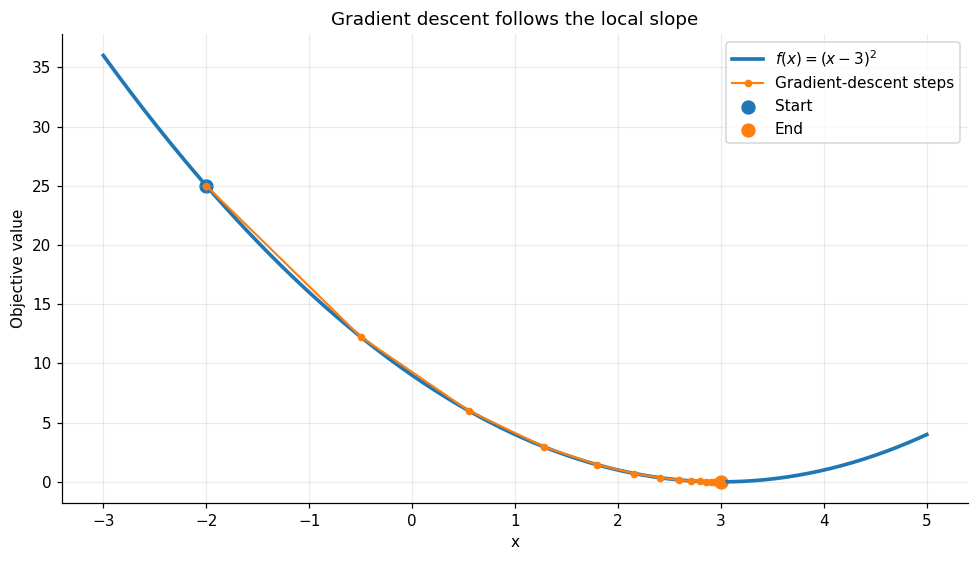

Saved figure: images/14_gradient_descent_path.png


In [53]:
# Plot the objective and optimization path.
xx = np.linspace(-3, 5, 300)
plt.figure()
plt.plot(xx, (xx - 3) ** 2, linewidth=2.4, label=r"$f(x)=(x-3)^2$")
plt.plot(positions, objective_values, marker="o", markersize=4, linewidth=1.4, label="Gradient-descent steps")
plt.scatter([positions[0]], [objective_values[0]], s=70, label="Start")
plt.scatter([positions[-1]], [objective_values[-1]], s=70, label="End")
plt.xlabel("x")
plt.ylabel("Objective value")
plt.title("Gradient descent follows the local slope")
plt.legend()
save_figure("14_gradient_descent_path.png")

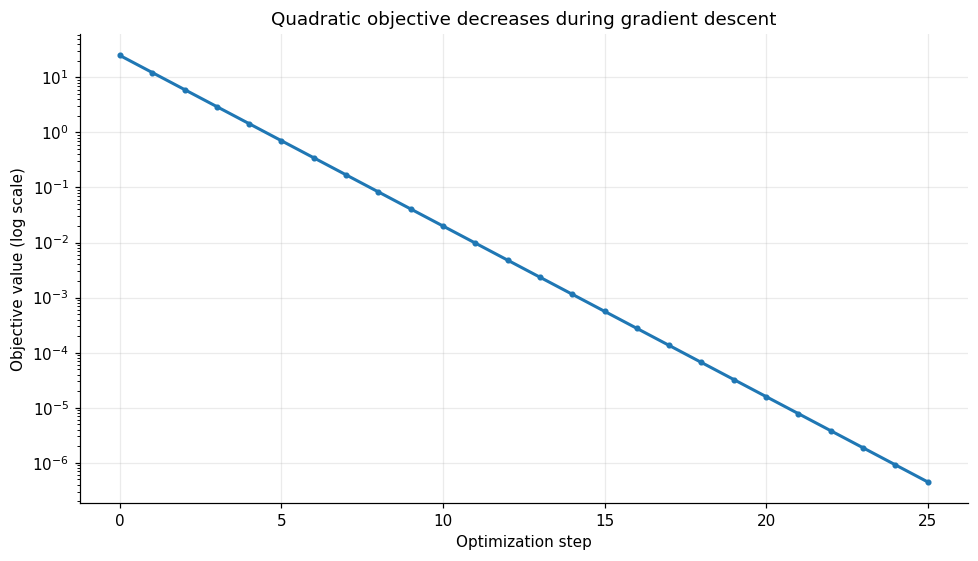

Saved figure: images/15_gradient_descent_convergence.png


In [54]:
# Plot the objective value at every optimization step.
plt.figure()
plt.plot(objective_values, marker="o", markersize=3, linewidth=2)
plt.yscale("log")
plt.xlabel("Optimization step")
plt.ylabel("Objective value (log scale)")
plt.title("Quadratic objective decreases during gradient descent")
save_figure("15_gradient_descent_convergence.png")

## 14. Common Autograd mistakes

Use these examples as a debugging checklist. Each problem is small, intentional, and paired with a safer pattern.

### Mistake 1 — forgetting `requires_grad=True`
If no input tensor requires gradients, PyTorch generally does not build the graph needed to compute the derivative.

In [55]:
x = torch.tensor(3.0)  # requires_grad=False by default
y = x ** 2
print("x.requires_grad:", x.requires_grad)
print("y.requires_grad:", y.requires_grad)

# Correct pattern:
x_tracked = torch.tensor(3.0, requires_grad=True)
y_tracked = x_tracked ** 2
y_tracked.backward()
print("Correct gradient:", x_tracked.grad.item())

x.requires_grad: False
y.requires_grad: False
Correct gradient: 6.0


### Mistake 2 — calling `.backward()` again on a consumed graph
By default, a backward pass releases saved graph data. Recompute the expression for a new pass, or use `retain_graph=True` only when you genuinely need to reuse the same graph.

In [56]:
# Safe pattern: recompute a fresh graph on every pass.
x = torch.tensor(2.0, requires_grad=True)
for _ in range(2):
    y = x ** 2
    x.grad = None
    y.backward()
    print("Fresh-pass gradient:", x.grad.item())

Fresh-pass gradient: 4.0
Fresh-pass gradient: 4.0


### Mistake 3 — forgetting to clear accumulated gradients
Without clearing, a second backward pass adds its gradient to the first. In model training, call `optimizer.zero_grad()` before `loss.backward()`.

In [57]:
# A compact demonstration of gradient accumulation.
x = torch.tensor(2.0, requires_grad=True)
(x**2).backward()
first = x.grad.item()
(x**2).backward()
second = x.grad.item()
print("After first backward :", first)
print("After second backward:", second)
x.grad = None
(x**2).backward()
print("After clearing first :", x.grad.item())

After first backward : 4.0
After second backward: 8.0
After clearing first : 4.0


### Mistake 4 — updating parameters while tracking gradients
Parameter updates are usually not part of the differentiable model graph. Use an optimizer (recommended) or update under `torch.no_grad()`.

In [58]:
# Correct manual update pattern.
parameter = torch.tensor(1.0, requires_grad=True)
loss = (parameter - 4) ** 2
loss.backward()
with torch.no_grad():
    parameter -= 0.1 * parameter.grad
parameter.grad = None
print("Updated parameter:", parameter.item())

Updated parameter: 1.600000023841858


### Mistake 5 — converting a gradient-tracking tensor directly to NumPy
NumPy does not track PyTorch's autograd graph. Detach the tensor first.

In [59]:
x = torch.tensor([1.0, 2.0, 3.0], requires_grad=True)
y = x ** 2
# Safe conversion for inspection or plotting:
y_numpy = y.detach().cpu().numpy()
print(y_numpy)

[1. 4. 9.]


## 15. Quick reference: the training-loop pattern

A typical PyTorch optimization step follows this order. Memorize the sequence, but remember that the model, loss function, and optimizer depend on the task.

In [60]:
# Minimal, generic single-step template (standalone example).
model = nn.Linear(1, 1)
optimizer = torch.optim.SGD(model.parameters(), lr=0.01)
loss_function = nn.MSELoss()

features = torch.tensor([[1.0], [2.0], [3.0]])
targets = torch.tensor([[2.0], [4.0], [6.0]])

optimizer.zero_grad(set_to_none=True)       # Clear accumulated gradients
predictions = model(features)               # Forward pass
loss = loss_function(predictions, targets)  # Scalar objective
loss.backward()                             # Compute gradients
optimizer.step()                            # Update parameters

print("Single-step loss:", loss.item())

Single-step loss: 16.11983871459961


## 16. Summary and mental checklist

Before finishing, make sure you can explain each statement in your own words:

- **`requires_grad=True`**: asks PyTorch to record operations needed for differentiation.
- **`grad_fn`**: points to the operation that created a tracked, non-leaf result.
- **`.backward()`**: propagates gradients backward from an output.
- **`.grad`**: stores accumulated gradients on leaf tensors and parameters.
- **`zero_grad()`**: clears gradients before the next training step.
- **`.detach()` / `torch.no_grad()`**: disconnect a value or a block of operations from gradient tracking.
- **Optimizer step**: uses computed gradients to update trainable parameters.
- **Loss curve**: helps you check whether training is making progress, but does not alone guarantee good generalization.

Autograd computes derivatives; it does not choose a good model, a suitable loss, a learning rate, or a training strategy for you.

## 17. Practice exercises

Try these without looking at the preceding solutions first. After each attempt, use Autograd to check your result.

1. For \(f(x)=3x^3-2x+1\), calculate the derivative at \(x=2\).
2. For \(z=\exp(2x)\), compare Autograd with the analytical derivative \(2\exp(2x)\).
3. Create two tensors `a` and `b` with `requires_grad=True`; differentiate \(L=(a-b)^2+ab\) with respect to both.
4. Repeat a backward pass twice and explain why the gradient doubles when you do not clear `.grad`.
5. Change the learning rate in the quadratic gradient-descent example. Compare convergence for a small, moderate, and overly large learning rate.
6. Change `mlp_epochs`, the hidden-layer size, or the learning rate and compare the loss/accuracy curves.
7. Add one extra feature to the synthetic classification dataset and retrain logistic regression.

### Exercise starter cell
Replace the function and point with your own experiment.

In [61]:
# Exercise starter: f(x) = 3x^3 - 2x + 1 at x = 2
x_exercise = torch.tensor(2.0, requires_grad=True)
f_exercise = 3 * x_exercise**3 - 2 * x_exercise + 1
f_exercise.backward()

print("Function value:", f_exercise.item())
print("Autograd derivative:", x_exercise.grad.item())
print("Manual derivative 9x^2 - 2:", 9 * (2.0**2) - 2)

Function value: 21.0
Autograd derivative: 34.0
Manual derivative 9x^2 - 2: 34.0


## 18. Generated figures

The notebook saves every chart into the `images/` folder using descriptive filenames. This final cell lists the generated assets so you can quickly confirm that the figures were created.

In [62]:
# List generated images in a deterministic order.
image_files = sorted(IMAGE_DIR.glob("*.png"))
print(f"Generated {len(image_files)} PNG figures in {IMAGE_DIR.resolve()}")
for file_path in image_files:
    print(f"- {file_path.name} ({file_path.stat().st_size / 1024:.1f} KB)")

Generated 15 PNG figures in /content/images
- 01_derivative_and_tangent.png (68.4 KB)
- 02_function_and_derivative.png (73.4 KB)
- 03_chain_rule_sin_x_squared.png (90.1 KB)
- 04_finite_difference_error.png (64.6 KB)
- 05_binary_cross_entropy.png (71.7 KB)
- 06_logistic_dataset.png (137.1 KB)
- 07_logistic_training_curves.png (56.4 KB)
- 08_logistic_decision_boundary.png (147.2 KB)
- 09_linear_regression_dataset.png (75.0 KB)
- 10_linear_regression_loss.png (37.1 KB)
- 11_linear_regression_fit.png (75.4 KB)
- 12_mlp_training_curves.png (57.9 KB)
- 13_mlp_gradient_norms.png (53.2 KB)
- 14_gradient_descent_path.png (72.6 KB)
- 15_gradient_descent_convergence.png (70.6 KB)
